<a href="https://colab.research.google.com/github/kahrees/the-compendium/blob/main/Probability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Counting**

In [1]:
import jax.numpy as jnp
from math import factorial

n, r = 10, 3

perm = factorial(n) // factorial(n - r)
comb = factorial(n) // (factorial(r) * factorial(n - r))

print(f"P({n},{r}) = {perm}")
print(f"C({n},{r}) = {comb}")
print(f"P / C = {perm // comb} (should equal {r}! = {factorial(r)})")

P(10,3) = 720
C(10,3) = 120
P / C = 6 (should equal 3! = 6)


In [2]:
from itertools import combinations

def comb_count(n, r):
    return factorial(n) // (factorial(r) * factorial(n - r))

# Formula approach
men_ways = comb_count(8, 3)
women_ways = comb_count(6, 2)
print(f"Formula: {men_ways} × {women_ways} = {men_ways * women_ways}")

# Enumeration approach
men = [f"M{i}" for i in range(1, 9)]
women = [f"W{i}" for i in range(1, 7)]
count = sum(1 for _ in combinations(men, 3) for _ in combinations(women, 2))
print(f"Enumeration: {count}")

Formula: 56 × 15 = 840
Enumeration: 840


In [3]:
n = 26
r = 4

with_rep = n ** r
without_rep = factorial(n) // factorial(n - r)

print(f"With repetition:    {with_rep:>10,}")
print(f"Without repetition: {without_rep:>10,}")
print(f"Fraction with repeats: {1 - without_rep/with_rep:.2%}")

With repetition:       456,976
Without repetition:    358,800
Fraction with repeats: 21.48%


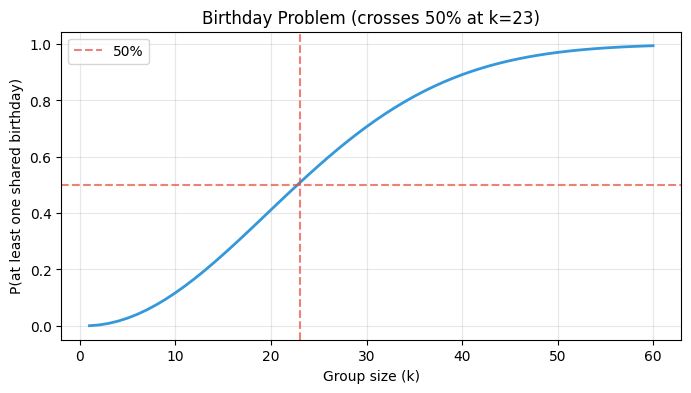

In [4]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

def birthday_prob_exact(k):
    """Probability of at least one shared birthday in group of k."""
    p_no_match = 1.0
    for i in range(k):
        p_no_match *= (365 - i) / 365
    return 1 - p_no_match

ks = list(range(1, 61))
probs = [birthday_prob_exact(k) for k in ks]

plt.figure(figsize=(8, 4))
plt.plot(ks, probs, color="#3498db", linewidth=2)
plt.axhline(y=0.5, color="#e74c3c", linestyle="--", alpha=0.7, label="50%")
cross = next(k for k, p in zip(ks, probs) if p >= 0.5)
plt.axvline(x=cross, color="#e74c3c", linestyle="--", alpha=0.7)
plt.xlabel("Group size (k)")
plt.ylabel("P(at least one shared birthday)")
plt.title(f"Birthday Problem (crosses 50% at k={cross})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **Probability Concepts**

In [5]:
key = jax.random.PRNGKey(42)
n = 100_000

# Generate population
k1, k2 = jax.random.split(key)
has_disease = jax.random.bernoulli(k1, p=0.01, shape=(n,))

# Generate test results
k3, k4 = jax.random.split(k2)
# Sensitivity: P(+|D) = 0.95, Specificity: P(-|D') = 0.90
test_positive = jnp.where(
    has_disease,
    jax.random.bernoulli(k3, p=0.95, shape=(n,)),
    jax.random.bernoulli(k4, p=0.10, shape=(n,))
)

# Among those who tested positive, what fraction actually has the disease?
positives = test_positive.astype(bool)
true_positives = (has_disease & positives).sum()
total_positives = positives.sum()

print(f"Total positive tests: {total_positives}")
print(f"True positives: {true_positives}")
print(f"P(Disease | Positive) = {true_positives / total_positives:.4f}")
print(f"Bayes' formula:         {0.95 * 0.01 / 0.1085:.4f}")

Total positive tests: 10877
True positives: 944
P(Disease | Positive) = 0.0868
Bayes' formula:         0.0876


In [6]:

key = jax.random.PRNGKey(0)
n = 200_000
k1, k2 = jax.random.split(key)

# Events: A = value < 0.4, B = value < 0.6 (overlap at < 0.4)
vals_a = jax.random.uniform(k1, shape=(n,))
vals_b = jax.random.uniform(k2, shape=(n,))

A = vals_a < 0.4
B = vals_b < 0.6

p_a = A.mean()
p_b = B.mean()
p_a_and_b = (A & B).mean()
p_a_or_b = (A | B).mean()

print(f"P(A) = {p_a:.4f}")
print(f"P(B) = {p_b:.4f}")
print(f"P(A ∩ B) = {p_a_and_b:.4f}")
print(f"P(A ∪ B) simulated = {p_a_or_b:.4f}")
print(f"P(A) + P(B) - P(A∩B) = {p_a + p_b - p_a_and_b:.4f}")

P(A) = 0.4019
P(B) = 0.6002
P(A ∩ B) = 0.2413
P(A ∪ B) simulated = 0.7608
P(A) + P(B) - P(A∩B) = 0.7608


In [7]:
key = jax.random.PRNGKey(1)
n = 500_000
k1, k2 = jax.random.split(key)

d1 = jax.random.randint(k1, shape=(n,), minval=1, maxval=7)
d2 = jax.random.randint(k2, shape=(n,), minval=1, maxval=7)
total = d1 + d2

# Unconditional
p_sum7 = (total == 7).mean()
print(f"P(sum=7) = {p_sum7:.4f} (exact: {6/36:.4f})")

# Conditional on first die = 3
mask = d1 == 3
p_sum7_given_d1_3 = (total[mask] == 7).mean()
print(f"P(sum=7 | d1=3) = {p_sum7_given_d1_3:.4f} (exact: {1/6:.4f})")

P(sum=7) = 0.1660 (exact: 0.1667)
P(sum=7 | d1=3) = 0.1669 (exact: 0.1667)


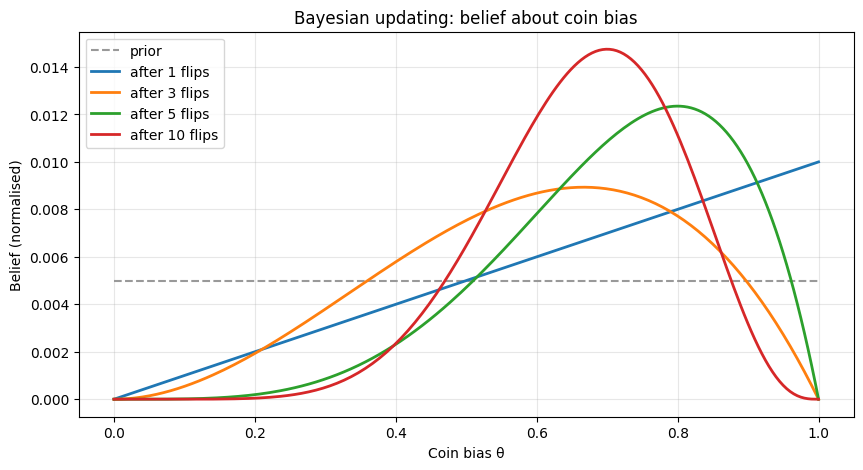

In [8]:
import jax.numpy as jnp
import matplotlib.pyplot as plt

def bayes_update(prior, likelihood):
    """Multiply prior by likelihood and normalise."""
    posterior = prior * likelihood
    return posterior / posterior.sum()

# Discretise possible bias values
theta = jnp.linspace(0, 1, 200)
prior = jnp.ones_like(theta)  # uniform prior
prior = prior / prior.sum()

# Observed flips: 1=heads, 0=tails
flips = [1, 1, 0, 1, 1, 1, 0, 1, 0, 1]

plt.figure(figsize=(10, 5))
plt.plot(theta, prior, "--", color="#999", label="prior")

for i, flip in enumerate(flips):
    likelihood = theta if flip == 1 else (1 - theta)
    prior = bayes_update(prior, likelihood)
    if i in [0, 2, 4, 9]:
        plt.plot(theta, prior, label=f"after {i+1} flips", linewidth=2)

plt.xlabel("Coin bias θ")
plt.ylabel("Belief (normalised)")
plt.title("Bayesian updating: belief about coin bias")
plt.legend()
plt.grid(alpha=0.3)
plt.show()